# End-to-End Statistics Project — E-commerce Customer Analysis

**Learning format:** every small task has its own code cell, followed immediately by an explanation of what the output means and what insight a Data Scientist should look for.

Run the notebook from top to bottom. Do not skip cells: later sections reuse variables created earlier.

**Dataset:** 1,000 synthetic website visits. Each row represents one visit; a visit may or may not convert into a purchase. This distinction lets us analyse conversion rate as well as order value among buyers.

## Project questions

- What does a typical order look like?
- How spread out are order values?
- Are there unusual observations?
- Are session time, items purchased, discount and spending associated?
- How do PMF, PDF, CDF and ECDF describe our variables?
- What happens to sample means when we repeatedly sample?
- How do standard error and CLT help us quantify uncertainty?
- What do confidence intervals and hypothesis tests tell management?

**Important distinction:** descriptive statistics describe the data we have. Inferential statistics use a sample to learn about a wider population.

## 1. Import libraries

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
SEED = 42
rng = np.random.default_rng(SEED)

**Insight:** NumPy handles numerical simulation, Pandas handles tabular data, Matplotlib/Seaborn create charts, and SciPy provides statistical distributions and tests. The fixed random seed makes the generated dataset reproducible.

## 2. Create the synthetic population — one variable at a time

In [6]:
N = 1000  # number of website visits in our simulated population

We are creating 1,000 visits. In this exercise, these 1,000 rows are our full simulated population. Later, we will select samples from it.

In [10]:
customer_age = np.clip(rng.normal(34, 11, N), 18, 75).round().astype(int)

Customer age is simulated around 34 years, with variation. `clip` keeps ages between 18 and 75. This is an artificial assumption, not a claim about real customers.

In [13]:
session_minutes = np.clip(rng.gamma(shape=2.4, scale=5.0, size=N), 0.5, 60)

Session time uses a gamma distribution, which produces a right-skewed positive variable. This gives us a useful example where the raw data need not be normally distributed.

In [16]:
items_purchased = np.clip(rng.poisson(lam=2.2, size=N) + 1, 1, 9)

Items purchased is discrete. A Poisson-based simulation is used because item counts are whole numbers. The minimum is one in this generated purchase-intent variable.

In [19]:
discount_percent = rng.choice([0, 5, 10, 15, 20, 25], N,
                                 p=[.18, .14, .25, .20, .16, .07])

Discount is a discrete percentage selected from six possible values. The probabilities sum to 1 and determine how often each discount occurs.

In [22]:
device = rng.choice(["Mobile", "Desktop"], N, p=[.68, .32])
customer_segment = rng.choice(["New", "Returning"], N, p=[.42, .58])

Device and customer segment are categorical variables. We deliberately create more mobile than desktop visits and more returning than new customers.

In [25]:
noise = rng.normal(0, 170, N)
order_value_before_conversion = (
    250 + 105 * items_purchased
    + 8.5 * session_minutes
    + 5.0 * discount_percent
    + np.where(customer_segment == "Returning", 90, 0)
    + noise
)
order_value_before_conversion = np.clip(order_value_before_conversion, 100, None)

We construct a spending amount using several inputs plus random noise. This creates designed relationships for learning. Because the data-generating process is known here, we can practise interpretation; in real data, the relationships are unknown.

In [28]:
outlier_idx = rng.choice(N, size=8, replace=False)
order_value_before_conversion[outlier_idx] *= rng.uniform(2.5, 4.0, size=8)

Eight randomly selected observations are multiplied to create unusually large potential purchases. These are intentional synthetic outliers for practising IQR and robust summaries.

In [31]:
logit = (
    -1.0 + 0.045 * session_minutes
    + 0.035 * discount_percent
    + np.where(customer_segment == "Returning", 0.45, 0)
    + np.where(device == "Desktop", 0.12, 0)
)
prob_conversion = 1 / (1 + np.exp(-logit))
converted = rng.binomial(1, prob_conversion, N)

This creates a conversion probability for each visit and then simulates a 0/1 outcome. The conversion probability varies with session time, discount, segment and device. This is a teaching simulation, not a causal model.

In [34]:
order_value = np.where(converted == 1, order_value_before_conversion, 0)

Non-converting visits have zero realised revenue. Keep this in mind: average revenue per visit and average order value among buyers are different metrics.

In [37]:
df = pd.DataFrame({
    "order_id": np.arange(1, N + 1),
    "customer_age": customer_age,
    "session_minutes": session_minutes.round(2),
    "items_purchased": items_purchased,
    "discount_percent": discount_percent,
    "order_value": order_value.round(2),
    "converted": converted,
    "device": device,
    "customer_segment": customer_segment
})
df.head()

,order_id,customer_age,session_minutes,items_purchased,discount_percent,order_value,converted,device,customer_segment
0,1,37,9.91,1,20,356.92,1,Mobile,Returning
1,2,23,7.63,2,0,0.00,0,Mobile,Returning
2,3,42,10.35,3,15,0.00,0,Desktop,Returning
3,4,44,15.94,5,10,0.00,0,Mobile,Returning
4,5,18,16.78,4,15,0.00,0,Mobile,Returning


**Insight:** each row is one visit, not necessarily a completed order. `converted` tells us whether a purchase happened; `order_value` is zero when no purchase happened. `order_id` is an identifier and should not be treated as a measured quantity.

## 3. Inspect the dataset

In [41]:
df.shape

(1000, 9)

The output is `(rows, columns)`. We expect 1,000 rows and 9 columns. This is a quick structural check.

In [44]:
df.head(10)

,order_id,customer_age,session_minutes,items_purchased,discount_percent,order_value,converted,device,customer_segment
0,1,37,9.91,1,20,356.92,1,Mobile,Returning
1,2,23,7.63,2,0,0.00,0,Mobile,Returning
2,3,42,10.35,3,15,0.00,0,Desktop,Returning
3,4,44,15.94,5,10,0.00,0,Mobile,Returning
4,5,18,16.78,4,15,0.00,0,Mobile,Returning
5,6,20,3.76,4,5,744.06,1,Desktop,New
6,7,35,7.14,2,0,0.00,0,Mobile,New
7,8,31,4.49,3,10,0.00,0,Desktop,Returning
8,9,34,10.71,2,15,1179.79,1,Desktop,Returning
9,10,25,8.10,3,5,741.09,1,Mobile,New


This displays the first 10 rows. Check whether values look plausible and whether the columns represent what you expect.

In [47]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   order_id          1000 non-null   int64  
 1   customer_age      1000 non-null   int64  
 2   session_minutes   1000 non-null   float64
 3   items_purchased   1000 non-null   int64  
 4   discount_percent  1000 non-null   int64  
 5   order_value       1000 non-null   float64
 6   converted         1000 non-null   int64  
 7   device            1000 non-null   object 
 8   customer_segment  1000 non-null   object 
dtypes: float64(2), int64(5), object(2)
memory usage: 70.4+ KB


This reports column names, data types and non-null counts. It helps identify unexpected types or missing values.

In [50]:
df.describe()

,order_id,customer_age,session_minutes,items_purchased,discount_percent,order_value,converted
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,500.500000,34.066000,12.169020,3.113000,11.225000,435.921470,0.534000
std,288.819436,10.131451,8.036179,1.437462,7.391144,460.940413,0.499092
min,1.000000,18.000000,0.500000,1.000000,0.000000,0.000000,0.000000
25%,250.750000,26.000000,6.402500,2.000000,5.000000,0.000000,0.000000
50%,500.500000,34.000000,10.635000,3.000000,10.000000,419.930000,1.000000
75%,750.250000,40.000000,16.115000,4.000000,15.000000,809.370000,1.000000
max,1000.000000,69.000000,51.620000,8.000000,25.000000,2849.660000,1.000000


This gives count, mean, standard deviation, minimum, quartiles and maximum for numeric columns. It is a first descriptive overview, not the complete analysis.

In [53]:
df.isna().sum()

order_id            0
customer_age        0
session_minutes     0
items_purchased     0
discount_percent    0
order_value         0
converted           0
device              0
customer_segment    0
dtype: int64

This counts missing values in each column. Missingness can bias analysis if it is systematic.

In [56]:
df.duplicated().sum()

0

This counts fully duplicated rows. A nonzero result would prompt investigation; duplicate order IDs should also be checked separately.

In [59]:
df["order_id"].nunique()

1000

Unique IDs should equal the number of rows if every visit has a distinct identifier.

## 4. Population and sample

In [63]:
population_mean_revenue_per_visit = df["order_value"].mean()
population_mean_revenue_per_visit

435.92147000000006

Because we generated all 1,000 rows, this is the exact population mean for this simulated population. In real projects, the population mean is usually unknown.

In [66]:
sample_srs = df.sample(n=100, random_state=SEED)
sample_srs.head()

,order_id,customer_age,session_minutes,items_purchased,discount_percent,order_value,converted,device,customer_segment
521,522,24,6.58,3,20,737.90,1,Mobile,New
737,738,43,9.48,2,15,0.00,0,Desktop,New
740,741,45,19.41,3,20,0.00,0,Desktop,New
660,661,18,1.48,1,10,0.00,0,Desktop,Returning
411,412,18,10.98,4,20,1211.42,1,Mobile,Returning


This is a simple random sample of 100 rows. Each row has an equal chance of selection. We use this sample for the next manual-style calculations.

In [69]:
print("Population size:", len(df))
print("Sample size:", len(sample_srs))

Population size: 1000
Sample size: 100


The sample is one-tenth of the simulated population. A sample statistic may differ from the population parameter because of sampling variability.

## 5. Other sampling methods

In [73]:
# Systematic sample: choose a random starting point, then every 10th row.
k = 10
start = rng.integers(0, k)
sample_systematic = df.iloc[start::k].head(100)
len(sample_systematic)

100

Systematic sampling selects every kth row after a starting point. It is convenient, but dangerous if the dataset is ordered in a repeating pattern.

In [76]:
# Stratified sample: take 10% from each customer segment.
sample_stratified = (
    df.groupby("customer_segment", group_keys=False)
      .sample(frac=0.10, random_state=SEED)
)
sample_stratified["customer_segment"].value_counts()

customer_segment
Returning    58
New          42
Name: count, dtype: int64

Stratified sampling ensures both New and Returning customers are represented. It is useful when subgroup representation matters.

In [79]:
for name, data in {
    "Simple random": sample_srs,
    "Systematic": sample_systematic,
    "Stratified": sample_stratified
}.items():
    print(name,
          "| n =", len(data),
          "| mean revenue/visit =", round(data["order_value"].mean(), 2),
          "| conversion rate =", round(data["converted"].mean(), 3))

Simple random | n = 100 | mean revenue/visit = 394.5 | conversion rate = 0.48
Systematic | n = 100 | mean revenue/visit = 536.02 | conversion rate = 0.61
Stratified | n = 100 | mean revenue/visit = 444.96 | conversion rate = 0.56


**Insight:** different samples can produce different estimates. A larger sample does not automatically remove selection bias. The sampling design must represent the population relevant to the business question.

## 6. Mean, median and mode

In [83]:
x = sample_srs["order_value"]  # includes zero-revenue non-converting visits
x.mean()

394.4986

The mean is total revenue divided by all sampled visits. Since non-converters have zero revenue, this is **revenue per visit**, not average order value among buyers.

In [86]:
x.median()

0.0

The median is the middle observation after sorting. If at least half the visits have zero revenue, the median may be zero. That is a meaningful feature of a visitor-level dataset.

In [89]:
x.mode().tolist()

[0.0]

Mode returns the most frequent observed value(s). Zero may be a mode because non-converting visits have zero revenue. For continuous variables, exact modes can be less useful because values may rarely repeat.

In [91]:
buyers_sample = sample_srs.loc[sample_srs["converted"] == 1, "order_value"]
buyers_sample.mean(), buyers_sample.median(), buyers_sample.mode().tolist()

(821.8720833333333,
 775.96,
 [390.12,
  398.73,
  452.29,
  466.21,
  499.96,
  514.33,
  522.56,
  570.08,
  590.65,
  598.06,
  602.34,
  638.19,
  641.97,
  643.48,
  671.06,
  671.54,
  697.74,
  701.84,
  716.08,
  737.9,
  741.16,
  743.3,
  753.39,
  769.32,
  782.6,
  784.93,
  788.55,
  833.62,
  857.35,
  923.75,
  951.08,
  964.99,
  966.43,
  988.35,
  1001.34,
  1016.93,
  1026.45,
  1082.65,
  1099.26,
  1139.04,
  1141.16,
  1144.12,
  1146.14,
  1163.75,
  1185.47,
  1211.42,
  1229.82,
  1288.36])

This separately calculates buyer-only order value. Always define the population behind a metric: all visits, converted visits, or unique customers.

In [ ]:
buyers_sample.describe()

Compare buyer-only summaries with all-visit summaries. This helps avoid mixing average order value with revenue per visitor.

## 7. Quartiles, percentiles and IQR

In [95]:
q1 = buyers_sample.quantile(0.25)
q2 = buyers_sample.quantile(0.50)
q3 = buyers_sample.quantile(0.75)
q1, q2, q3

(641.0250000000001, 775.96, 1019.31)

Q1, Q2 and Q3 are the 25th, 50th and 75th percentiles. Pandas uses linear interpolation by default, so different software conventions can produce slightly different quartiles.

In [98]:
iqr = q3 - q1
iqr

378.28499999999985

IQR is the spread of the middle 50% of buyer order values. It is less sensitive to extreme values than the full range.

In [101]:
lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr
lower_fence, upper_fence

(73.59750000000031, 1586.7374999999997)

The 1.5 × IQR fences are a common rule for flagging potential outliers. They are not proof that a value is erroneous.

In [104]:
outliers = buyers_sample[
    (buyers_sample < lower_fence) | (buyers_sample > upper_fence)
]
outliers.sort_values(ascending=False)

Series([], Name: order_value, dtype: float64)

Inspect the flagged values. Ask whether they are genuine large purchases, data errors, or unusual customer behaviour. Do not automatically delete them.

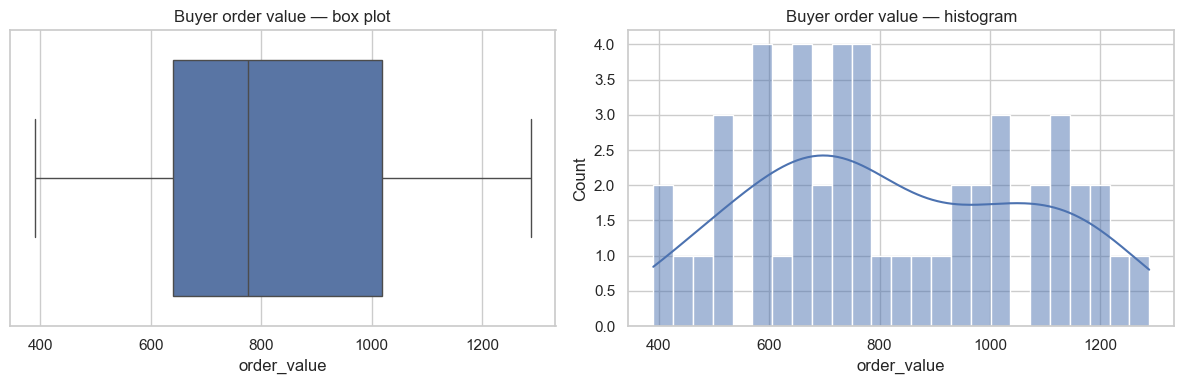

In [106]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(x=buyers_sample, ax=axes[0])
axes[0].set_title("Buyer order value — box plot")
sns.histplot(buyers_sample, bins=25, kde=True, ax=axes[1])
axes[1].set_title("Buyer order value — histogram")
plt.tight_layout()
plt.show()

The box plot shows median, quartiles and potential outliers. The histogram shows the distribution's shape. Look for skewness, multiple peaks and extreme values.

## 8. Variance and standard deviation

In [108]:
sample_variance = buyers_sample.var(ddof=1)
sample_variance

61659.58619982269

Pandas uses `ddof=1` by default: it divides by n−1 to calculate sample variance. Variance is in squared rupees, so it is not as intuitive to communicate.

In [111]:
sample_sd = buyers_sample.std(ddof=1)
sample_sd

248.3134837253561

Standard deviation is the square root of variance and is measured in rupees. It describes the spread of individual buyer order values around their sample mean.

In [114]:
buyers_sample_no_outliers = buyers_sample[
    (buyers_sample >= lower_fence) & (buyers_sample <= upper_fence)
]
pd.Series({
    "Mean with potential outliers": buyers_sample.mean(),
    "Mean without flagged values": buyers_sample_no_outliers.mean(),
    "SD with potential outliers": buyers_sample.std(ddof=1),
    "SD without flagged values": buyers_sample_no_outliers.std(ddof=1)
})

Mean with potential outliers    821.872083
Mean without flagged values     821.872083
SD with potential outliers      248.313484
SD without flagged values       248.313484
dtype: float64

This comparison demonstrates how extreme observations can influence mean and SD. Do not use the filtered results as the official answer unless you have a defensible business/data-quality reason to exclude those records.

## 9. Covariance and correlation

In [ ]:
relationship_data = sample_srs[
    ["session_minutes", "items_purchased", "discount_percent", "order_value"]
]
relationship_data.cov()

Covariance indicates whether pairs of variables tend to move together. Positive means they tend to move in the same direction; negative means opposite directions. Its magnitude depends on units.

In [ ]:
relationship_data.corr(method="pearson")

Pearson correlation standardises linear association to a range from −1 to +1. Values near +1 indicate strong positive linear association; values near −1 strong negative linear association; values near zero little linear association.

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.scatterplot(data=sample_srs, x="session_minutes", y="order_value", ax=axes[0])
axes[0].set_title("Session time vs revenue per visit")
sns.scatterplot(data=sample_srs, x="items_purchased", y="order_value", ax=axes[1])
axes[1].set_title("Items purchased vs revenue per visit")
plt.tight_layout()
plt.show()

Scatter plots let you inspect shape, clusters and outliers. Correlation does not establish causation. A near-zero Pearson correlation also does not rule out a nonlinear relationship.

## 10. PMF, PDF, CDF and ECDF

In [116]:
pmf = sample_srs["items_purchased"].value_counts(normalize=True).sort_index()
pmf

items_purchased
1    0.13
2    0.33
3    0.27
4    0.12
5    0.09
6    0.03
7    0.02
8    0.01
Name: proportion, dtype: float64

This is an empirical PMF: the observed probability of each discrete item count. The probabilities should sum to 1.

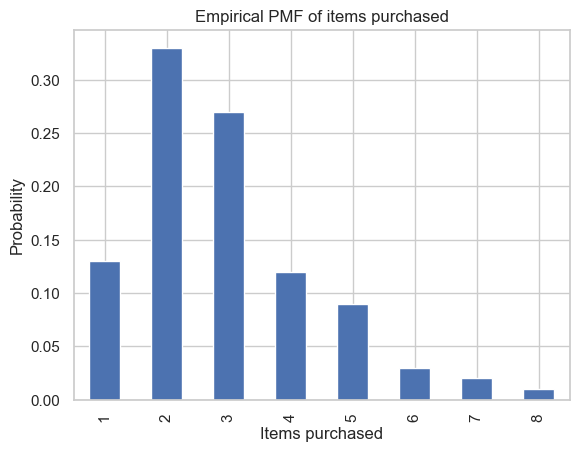

In [118]:
pmf.plot(kind="bar", xlabel="Items purchased", ylabel="Probability",
          title="Empirical PMF of items purchased")
plt.show()

Each bar gives the probability of exactly that number of items. This is appropriate for discrete counts.

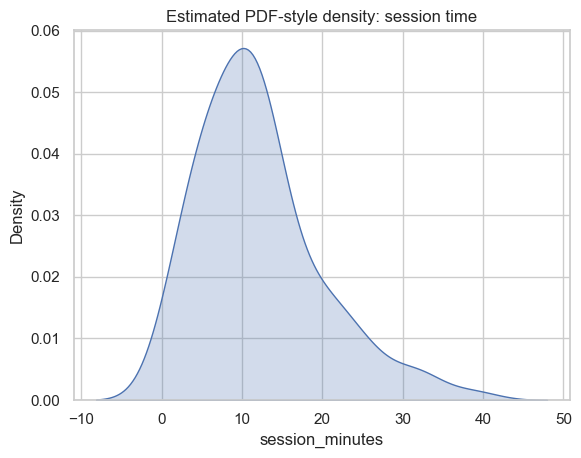

In [121]:
sns.kdeplot(data=sample_srs, x="session_minutes", fill=True)
plt.title("Estimated PDF-style density: session time")
plt.show()

A KDE is a smoothed density estimate for a continuous variable. Probability over an interval corresponds to area under the density curve, not the height at one exact point.

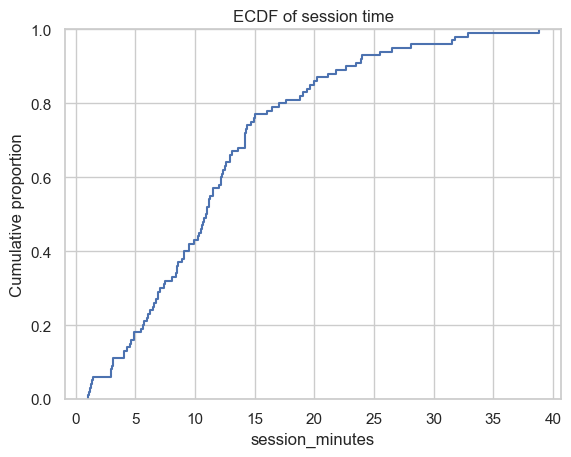

In [123]:
sns.ecdfplot(data=sample_srs, x="session_minutes")
plt.title("ECDF of session time")
plt.ylabel("Cumulative proportion")
plt.show()

The ECDF gives the fraction of observed sessions at or below each x-value. It is an empirical version of a CDF.

In [ ]:
fraction_sessions_10_or_less = (sample_srs["session_minutes"] <= 10).mean()
fraction_sessions_10_or_less

This directly estimates the sample proportion of sessions lasting 10 minutes or less. Compare it with the ECDF value at 10.

## 11. Binomial distribution and conversion

In [125]:
n_visits = len(sample_srs)
conversions = int(sample_srs["converted"].sum())
p_hat = conversions / n_visits
n_visits, conversions, p_hat

(100, 48, 0.48)

The observed conversion rate is conversions divided by visits. Each visit is treated as a Bernoulli outcome: converted (1) or not converted (0).

In [127]:
assumed_p = 0.30
prob_exactly_35 = stats.binom.pmf(35, n=100, p=assumed_p)
prob_at_least_35 = stats.binom.sf(34, n=100, p=assumed_p)
prob_exactly_35, prob_at_least_35

(0.04677968235272977, 0.16285828837178706)

This answers two different probability questions under an assumed 30% conversion probability: exactly 35 conversions, and at least 35. The assumed p is illustrative; do not confuse it with the observed sample rate.

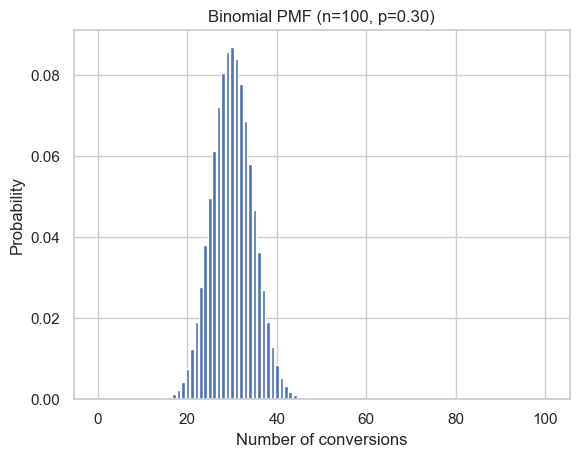

In [129]:
k_values = np.arange(0, 101)
plt.bar(k_values, stats.binom.pmf(k_values, n=100, p=assumed_p))
plt.xlabel("Number of conversions")
plt.ylabel("Probability")
plt.title("Binomial PMF (n=100, p=0.30)")
plt.show()

A binomial model assumes a fixed number of trials, two outcomes per trial, constant success probability and independent trials (or a reasonable approximation).

## 12. Normal distribution and z-scores

In [131]:
buyer_mean = buyers_sample.mean()
buyer_sd = buyers_sample.std(ddof=1)
buyer_mean, buyer_sd

(821.8720833333333, 248.3134837253561)

We calculate the buyer-only sample mean and SD. These are estimates from our sample, not known population parameters.

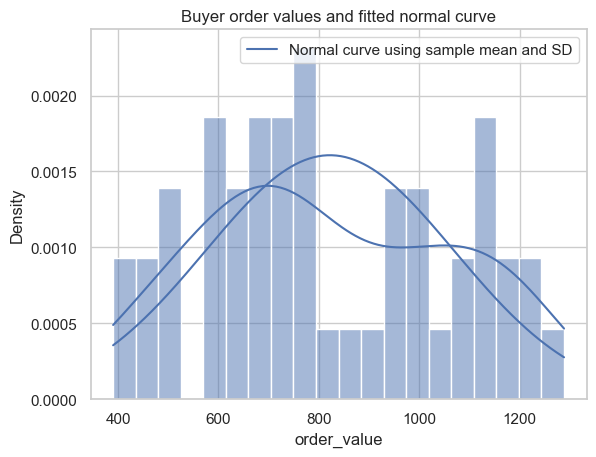

In [133]:
sns.histplot(buyers_sample, stat="density", bins=20, kde=True)
grid = np.linspace(buyers_sample.min(), buyers_sample.max(), 300)
plt.plot(grid, stats.norm.pdf(grid, buyer_mean, buyer_sd),
         label="Normal curve using sample mean and SD")
plt.legend()
plt.title("Buyer order values and fitted normal curve")
plt.show()

Compare the observed distribution with the fitted normal curve. Strong skewness or extreme tails indicate that raw order values may not be well modelled by a normal distribution.

In [135]:
value_to_check = 1000
z_score = (value_to_check - buyer_mean) / buyer_sd
z_score

0.7173509629613298

The z-score tells how many sample standard deviations the value is above or below the sample mean. Positive means above; negative means below.

In [138]:
normal_model_cdf = stats.norm.cdf(value_to_check, loc=buyer_mean, scale=buyer_sd)
normal_model_cdf

0.7634212155765878

This is the cumulative probability under the fitted normal model. Treat it as a model-based approximation, not an exact empirical probability.

## 13. Sampling distribution and standard error

In [142]:
B = 2000
sample_size = 40
sample_means = np.array([
    df["order_value"].sample(n=sample_size, replace=True,
                             random_state=i).mean()
    for i in range(B)
])

We repeatedly draw 2,000 samples of 40 visits, with replacement, and calculate each sample mean. This creates a simulated sampling distribution.

In [144]:
sample_means.mean(), sample_means.std(ddof=1)

(434.28938187499995, 75.36347901318732)

The mean of simulated sample means should be near the population mean. The SD of these sample means estimates the standard error for this sample size.

In [147]:
estimated_se = df["order_value"].std(ddof=0) / np.sqrt(sample_size)
estimated_se

72.84462889529678

The theoretical SE approximation is population SD divided by square root of sample size. In real work, population SD is unknown, so we commonly use sample SD.

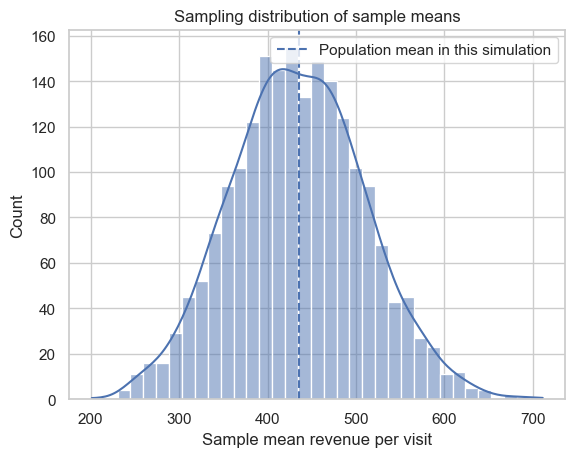

In [150]:
sns.histplot(sample_means, bins=35, kde=True)
plt.axvline(df["order_value"].mean(), linestyle="--",
            label="Population mean in this simulation")
plt.title("Sampling distribution of sample means")
plt.xlabel("Sample mean revenue per visit")
plt.legend()
plt.show()

The sampling distribution is the distribution of a statistic across repeated samples. Standard deviation describes individual observations; standard error describes the sampling variability of an estimate.

## 14. Central Limit Theorem

In [152]:
skewed_population = rng.exponential(scale=1.0, size=100000)
stats.skew(skewed_population)

2.0278975302973685

The exponential population is strongly right-skewed. We use it to demonstrate that the original data do not need to be normal for the CLT to be useful.

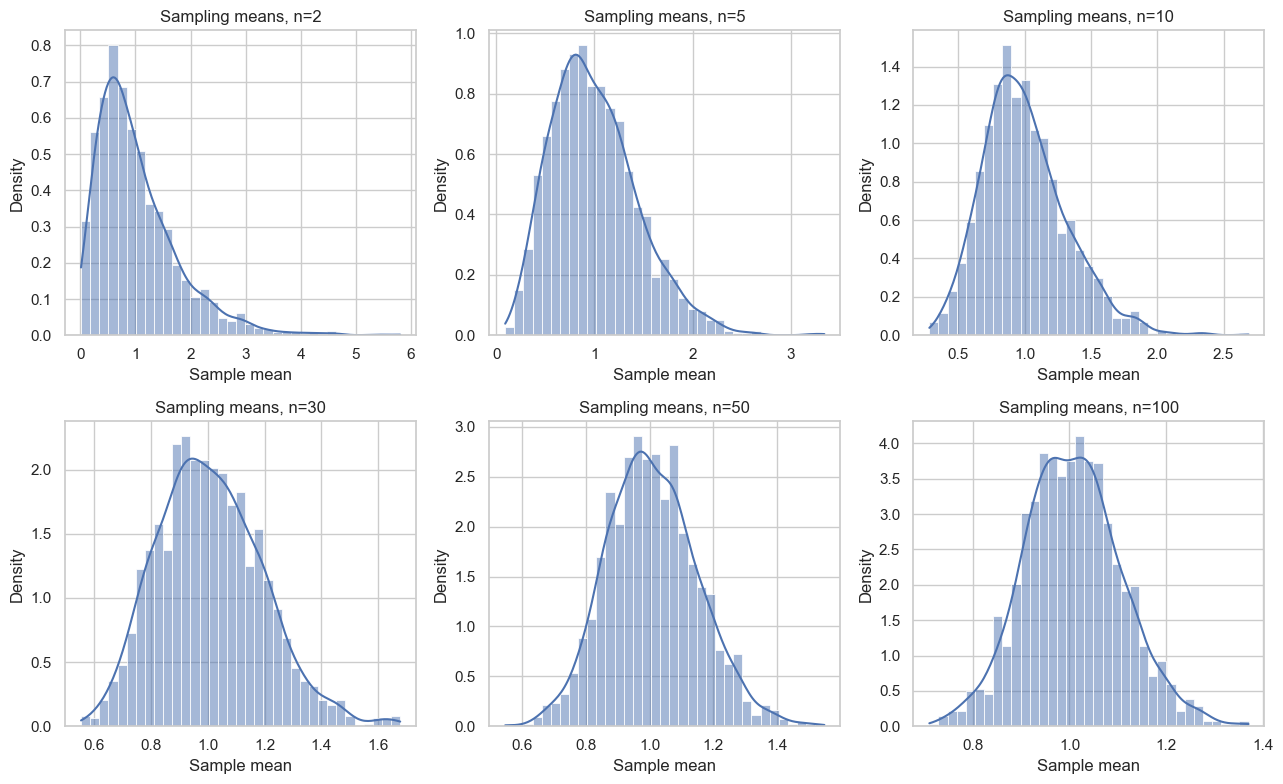

In [155]:
sample_sizes = [2, 5, 10, 30, 50, 100]
fig, axes = plt.subplots(2, 3, figsize=(13, 8))
for ax, n in zip(axes.flat, sample_sizes):
    means = [
        rng.choice(skewed_population, size=n, replace=True).mean()
        for _ in range(1500)
    ]
    sns.histplot(means, bins=35, stat="density", kde=True, ax=ax)
    ax.set_title(f"Sampling means, n={n}")
    ax.set_xlabel("Sample mean")
plt.tight_layout()
plt.show()

As sample size increases, the distribution of sample means generally becomes more bell-shaped and narrower. CLT is about sample means, not the raw population. n=30 is a rule of thumb, not a guarantee; skewness, heavy tails and dependence matter.

## 15. Confidence interval for mean buyer order value

In [157]:
n_buyers = len(buyers_sample)
x_bar = buyers_sample.mean()
s = buyers_sample.std(ddof=1)
se = s / np.sqrt(n_buyers)
n_buyers, x_bar, s, se

(48, 821.8720833333333, 248.3134837253561, 35.84096416806203)

We calculate sample size, sample mean, sample SD and standard error for buyer-only order values. The standard error quantifies estimated sample-mean uncertainty.

In [159]:
confidence_level = 0.95
alpha = 1 - confidence_level
t_critical = stats.t.ppf(1 - alpha/2, df=n_buyers - 1)
margin_of_error = t_critical * se
ci_lower = x_bar - margin_of_error
ci_upper = x_bar + margin_of_error
ci_lower, ci_upper

(749.7693636653061, 893.9748030013606)

We use a t critical value because the population SD is unknown and estimated with the sample SD. The interval is for the mean order value among buyers, not revenue per visit.

In [161]:
print(f"95% CI for mean buyer order value: ₹{ci_lower:,.2f} to ₹{ci_upper:,.2f}")

95% CI for mean buyer order value: ₹749.77 to ₹893.97


Frequentist interpretation: if we repeatedly took comparable random samples and built intervals this way, about 95% of intervals would contain the fixed population mean. It is not a 95% probability statement about this already-calculated interval.

## 16. Confidence interval for conversion rate

In [163]:
successes = int(sample_srs["converted"].sum())
n = len(sample_srs)
p_hat = successes / n
z_critical = stats.norm.ppf(0.975)
successes, n, p_hat

(48, 100, 0.48)

The sample conversion rate is a proportion. We use a Wilson interval because the simple Wald interval can behave poorly, especially with small samples or proportions near 0 or 1.

In [165]:
denom = 1 + z_critical**2 / n
center = (p_hat + z_critical**2 / (2*n)) / denom
half_width = (z_critical * np.sqrt(
    p_hat*(1-p_hat)/n + z_critical**2/(4*n**2)
)) / denom
wilson_lower = center - half_width
wilson_upper = center + half_width
wilson_lower, wilson_upper

(0.384645517580519, 0.5768342223477603)

The interval gives a range of plausible values for the population conversion proportion under the sampling assumptions. Report the point estimate and the interval together.

In [168]:
print(f"Sample conversion rate: {p_hat:.1%}")
print(f"95% Wilson CI: {wilson_lower:.1%} to {wilson_upper:.1%}")

Sample conversion rate: 48.0%
95% Wilson CI: 38.5% to 57.7%


A wider interval means more uncertainty. Increasing sample size generally narrows the interval, assuming the sample remains representative.

## 17. Hypothesis test: is mean buyer order value different from ₹1,000?

In [171]:
benchmark = 1000
t_statistic, p_value = stats.ttest_1samp(buyers_sample, popmean=benchmark)
t_statistic, p_value

(-4.969953258829932, 9.311095350639008e-06)

Null hypothesis H0: population mean buyer order value equals ₹1,000. Alternative H1: it differs from ₹1,000. This is a two-sided one-sample t-test.

In [173]:
alpha = 0.05
if p_value < alpha:
    print("Reject H0 at the 5% significance level.")
else:
    print("Fail to reject H0 at the 5% significance level.")

Reject H0 at the 5% significance level.


The p-value is the probability, assuming H0 and the test assumptions are true, of observing a test statistic at least as extreme as ours. It is not the probability that H0 is true. Failing to reject H0 does not prove H0.

## 18. Compare new and returning buyers

In [175]:
new_buyer_orders = sample_srs.loc[
    (sample_srs["customer_segment"] == "New") &
    (sample_srs["converted"] == 1), "order_value"
]
returning_buyer_orders = sample_srs.loc[
    (sample_srs["customer_segment"] == "Returning") &
    (sample_srs["converted"] == 1), "order_value"
]
new_buyer_orders.mean(), returning_buyer_orders.mean()

(822.1431818181819, 821.6426923076924)

This compares buyer-only average order values for the two customer segments. Check group sizes too; very small groups give unstable estimates.

In [177]:
welch_t, welch_p = stats.ttest_ind(
    returning_buyer_orders,
    new_buyer_orders,
    equal_var=False,
    nan_policy="omit"
)
welch_t, welch_p

(-0.006845036955170116, 0.9945697369316236)

Welch's independent two-sample t-test compares group means without assuming equal variances. This is observational data, so a difference does not prove that customer segment causes higher spending.

## 19. Summarise the business metrics

In [179]:
buyers_all = df.loc[df["converted"] == 1, "order_value"]
business_summary = pd.Series({
    "Total visits": len(df),
    "Conversions": int(df["converted"].sum()),
    "Conversion rate": df["converted"].mean(),
    "Total revenue": df["order_value"].sum(),
    "Revenue per visit": df["order_value"].mean(),
    "Average order value among buyers": buyers_all.mean(),
    "Median order value among buyers": buyers_all.median(),
    "SD of buyer order value": buyers_all.std(ddof=1)
})
business_summary

Total visits                          1000.000000
Conversions                            534.000000
Conversion rate                          0.534000
Total revenue                       435921.470000
Revenue per visit                      435.921470
Average order value among buyers       816.332341
Median order value among buyers        788.635000
SD of buyer order value                295.127194
dtype: float64

This summary separates conversion, revenue per visit and average order value. Those metrics answer different questions and should not be used interchangeably.

## 20. Write your findings like a Data Scientist

For every conclusion, write:

1. **Observation:** what did the data show?
2. **Evidence:** which statistic, plot, interval or test supports it?
3. **Business meaning:** why should management care?
4. **Caveat:** what can we not conclude? What else should be checked?

Example template:

> The sample conversion rate was __%. Its 95% Wilson confidence interval was __% to __%. Under the sampling assumptions, this interval gives a plausible range for the population conversion rate. Before changing campaign spend, we should compare campaigns using a properly designed experiment.

## 21. Interview practice

Try answering these without looking at the earlier cells:

1. Why can median be more useful than mean for skewed order values?
2. What does IQR measure?
3. Why does sample variance use n−1?
4. How is standard deviation different from standard error?
5. What does a positive covariance tell us?
6. Why is correlation not causation?
7. What is the difference between PMF and PDF?
8. Why does a PDF value not represent the probability of one exact continuous value?
9. What does the CLT say, and what does it not say?
10. What does a 95% confidence interval mean?
11. What does p = 0.03 mean under a hypothesis test?
12. Why might a statistically significant result have little business value?

**Final challenge:** choose one finding from the notebook and explain it to a non-technical manager in three sentences.